## 1. Mount Google Drive


In [2]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import shutil
import time
import zipfile

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Colab Notebooks/Contextual Emotion Recognition"
)
EMOTIC_ROOT = PROJECT_DIR / "data/raw/raw/emotic"

PAMI_ROOT = EMOTIC_ROOT / "PAMI"
PAMI_ANNOTATION_PATH = (
    PAMI_ROOT / "Annotations/Annotations/Annotations.mat"
)
PAMI_IMAGE_ARCHIVE = PAMI_ROOT / "pami_emotic.zip"

CVPR_ROOT = EMOTIC_ROOT / "CVPR"
CVPR_ANNOTATION_PATH = CVPR_ROOT / "CVPR17_Annotations.mat"
CVPR_IMAGE_ARCHIVE = CVPR_ROOT / "cvpr_emotic.zip"

paths_to_check = {
    "PAMI annotation": PAMI_ANNOTATION_PATH,
    "PAMI images": PAMI_IMAGE_ARCHIVE,
    "CVPR annotation": CVPR_ANNOTATION_PATH,
    "CVPR images": CVPR_IMAGE_ARCHIVE,
}

for name, path in paths_to_check.items():
    print(f"{name:16}: {path.exists()}  {path}")

missing = [name for name, path in paths_to_check.items() if not path.exists()]
assert not missing, f"Không tìm thấy: {missing}"


def extract_images(archive_path, extract_dir, root_name, expected_files):
    """Giải nén zip ảnh từ Drive vào ổ local của Colab, mỗi runtime một lần."""
    image_root = extract_dir / root_name
    marker = extract_dir / ".extracted"
    if marker.is_file():
        return image_root
    assert archive_path.is_file(), f"Thiếu file zip: {archive_path}"
    shutil.rmtree(extract_dir, ignore_errors=True)
    extract_dir.mkdir(parents=True)
    started = time.time()
    with zipfile.ZipFile(archive_path) as archive:
        archive.extractall(extract_dir)
    file_count = sum(1 for path in image_root.rglob("*") if path.is_file())
    assert file_count == expected_files, (
        f"{archive_path.name}: {file_count} file, cần {expected_files}"
    )
    marker.touch()
    print(f"Giải nén {archive_path.name}: {file_count:,} file, {time.time() - started:.0f}s")
    return image_root


# Ảnh lưu trên Drive dưới dạng zip và được giải nén vào /content, vì đọc
# hàng chục nghìn ảnh nhỏ trực tiếp từ Drive khiến GPU phải chờ dữ liệu.
LOCAL_EMOTIC_ROOT = Path("/content/emotic")
PAMI_IMAGE_ROOT = extract_images(PAMI_IMAGE_ARCHIVE, LOCAL_EMOTIC_ROOT / "PAMI", "emotic", 23185)
CVPR_IMAGE_ROOT = extract_images(CVPR_IMAGE_ARCHIVE, LOCAL_EMOTIC_ROOT / "CVPR", "cvpr_emotic", 18302)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PAMI annotation : True  /content/drive/MyDrive/Colab Notebooks/Contextual Emotion Recognition/data/raw/raw/emotic/PAMI/Annotations/Annotations/Annotations.mat
PAMI images     : True  /content/drive/MyDrive/Colab Notebooks/Contextual Emotion Recognition/data/raw/raw/emotic/PAMI/emotic/emotic
CVPR annotation : True  /content/drive/MyDrive/Colab Notebooks/Contextual Emotion Recognition/data/raw/raw/emotic/CVPR/CVPR17_Annotations.mat
CVPR images     : True  /content/drive/MyDrive/Colab Notebooks/Contextual Emotion Recognition/data/raw/raw/emotic/CVPR/cvpr_emotic/cvpr_emotic


## 2. Import annotation PAMI và CVPR


In [3]:
import numpy as np
from scipy.io import loadmat


def as_list(value):
    """Chuyển MATLAB cell/NumPy array/scalar thành Python list."""
    if value is None:
        return []
    if isinstance(value, np.ndarray):
        return value.reshape(-1).tolist()
    if isinstance(value, (list, tuple)):
        return list(value)
    return [value]


def load_emotic_mat(annotation_path):
    """Đọc file annotation EMOTIC và trả về các split có trong file."""
    raw = loadmat(annotation_path, simplify_cells=True)
    return {
        split: as_list(raw[split])
        for split in ("train", "val", "test")
        if split in raw
    }


def count_people(records):
    total = 0
    for record in records:
        if isinstance(record, dict):
            total += len(as_list(record.get("person")))
    return total


EMOTIC_DATASETS = {
    "PAMI": {
        "annotation_path": PAMI_ANNOTATION_PATH,
        # PAMI có thể tham chiếu ảnh thuộc nhiều nguồn EMOTIC.
        "image_roots": (PAMI_IMAGE_ROOT, CVPR_IMAGE_ROOT),
    },
    "CVPR": {
        "annotation_path": CVPR_ANNOTATION_PATH,
        "image_roots": (CVPR_IMAGE_ROOT,),
    },
}

annotations = {}
for dataset_name, config in EMOTIC_DATASETS.items():
    splits = load_emotic_mat(config["annotation_path"])
    annotations[dataset_name] = splits
    print(f"\n{dataset_name}")
    for split_name, records in splits.items():
        print(
            f"  {split_name:5}: "
            f"{len(records):6d} images, "
            f"{count_people(records):6d} person annotations"
        )



PAMI
  train:  17077 images,  23706 person annotations
  val  :   2088 images,   3334 person annotations
  test :   4389 images,   7280 person annotations

CVPR
  train:  12915 images,  16001 person annotations
  val  :   1705 images,   2397 person annotations
  test :   3682 images,   5369 person annotations


## 3. Kiểm tra khả năng tìm ảnh từ annotation


In [4]:
def relative_image_path(record):
    folder = str(record.get("folder", "")).strip()
    filename = str(record.get("filename", "")).strip()
    return Path(folder) / filename


def find_image(record, image_roots):
    relative_path = relative_image_path(record)
    for root in image_roots:
        candidate = root / relative_path
        if candidate.is_file():
            return candidate
    return None


for dataset_name, splits in annotations.items():
    image_roots = EMOTIC_DATASETS[dataset_name]["image_roots"]
    print(f"\n{dataset_name}")
    for split_name, records in splits.items():
        sample_records = records[:100]
        found = sum(
            find_image(record, image_roots) is not None
            for record in sample_records
            if isinstance(record, dict)
        )
        print(
            f"  {split_name:5}: tìm thấy {found}/{len(sample_records)} "
            "ảnh đầu tiên"
        )



PAMI
  train: tìm thấy 93/100 ảnh đầu tiên
  val  : tìm thấy 95/100 ảnh đầu tiên
  test : tìm thấy 90/100 ảnh đầu tiên

CVPR
  train: tìm thấy 100/100 ảnh đầu tiên
  val  : tìm thấy 100/100 ảnh đầu tiên
  test : tìm thấy 100/100 ảnh đầu tiên


## 4. Hiển thị một mẫu và bounding box

Đổi `DATASET_NAME` thành `"CVPR"` nếu muốn kiểm tra phiên bản CVPR.



Person 0
  bbox: [86.0, 58.0, 564.0, 628.0]
  categories: {'categories': array(['Disconnection', 'Doubt/Confusion'], dtype=object)}
  continuous/VAD: {'valence': 5, 'arousal': 3, 'dominance': 9}

Image path: /content/drive/MyDrive/Colab Notebooks/Contextual Emotion Recognition/data/raw/raw/emotic/CVPR/cvpr_emotic/cvpr_emotic/mscoco/images/COCO_val2014_000000562243.jpg


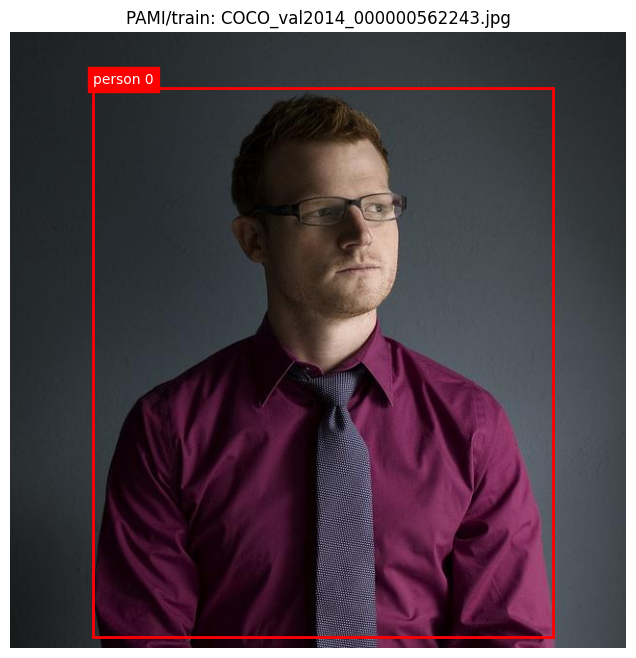

In [5]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

DATASET_NAME = "PAMI"
SPLIT_NAME = "train"

records = annotations[DATASET_NAME][SPLIT_NAME]
image_roots = EMOTIC_DATASETS[DATASET_NAME]["image_roots"]

record = None
image_path = None
for candidate_record in records:
    if not isinstance(candidate_record, dict):
        continue
    candidate_path = find_image(candidate_record, image_roots)
    if candidate_path is not None:
        record = candidate_record
        image_path = candidate_path
        break

assert record is not None, "Không tìm thấy ảnh tương ứng với annotation."

image = Image.open(image_path).convert("RGB")
fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(image)
ax.set_title(f"{DATASET_NAME}/{SPLIT_NAME}: {image_path.name}")
ax.axis("off")

people = as_list(record.get("person"))
for person_index, person in enumerate(people):
    if not isinstance(person, dict):
        continue
    bbox = np.asarray(person.get("body_bbox"), dtype=float).reshape(-1)
    if bbox.size != 4:
        continue
    x1, y1, x2, y2 = bbox
    ax.add_patch(
        Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            edgecolor="red",
            linewidth=2,
        )
    )
    ax.text(
        x1,
        max(0, y1 - 5),
        f"person {person_index}",
        color="white",
        backgroundcolor="red",
    )
    print(f"\nPerson {person_index}")
    print("  bbox:", bbox.tolist())
    print("  categories:", person.get("annotations_categories"))
    print("  continuous/VAD:", person.get("annotations_continuous"))

print("\nImage path:", image_path)
plt.show()
